# Line-detection by rotation 

Based on the assertion that horizontal lines are easier to detect than oblique lines, we suggest to rotate images in order to find an angle at which we detect a horizontal line

### Imports

In [14]:
import json
import os
import numpy as np
from src.dataset import NoisePatchDataset
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

import torchvision.transforms.functional as TF


Loading data and annotations

In [7]:
import os
import json
import numpy as np

def get_linked_dataset(dataset_dir: str):
    """
    Loads annotations and links them with their respective image patch data.
    """
    annotations_path = os.path.join(dataset_dir, "annotations.json")
    test_dir = os.path.join(dataset_dir, "test")

    # 1. Load the annotations dictionary {filename: {"horizontal": bool, "other": bool}}
    with open(annotations_path, "r") as f:
        annotations = json.load(f)

    linked_data = []
    
    # 2. Iterate through each annotated patch file
    for filename, labels in annotations.items():
        patch_path = os.path.join(test_dir, filename)
        
        if os.path.exists(patch_path):
            # 3. Load the patch data from the .npy file
            patch = np.load(patch_path)
            
            if patch.ndim == 2:
                patch = patch[None, :, :]
            elif patch.ndim != 3 or patch.shape[0] != 1:
                raise ValueError(
                    f"Invalid patch shape {patch.shape} in file {patch_path}"
                )
    
            patch = patch.astype(np.float32)
            patch -= patch.mean()
            patch /= (patch.std() + 1e-8)
    
            patch =  torch.from_numpy(patch)
            
            # Combine image data and annotations together
            linked_data.append({
                "filename": filename,
                "image": patch,
                "horizontal": labels["horizontal"],
                "other": labels["other"]
            })
            
    return linked_data


dataset = get_linked_dataset("./dataset/")


### Detecting horizontal lines

0


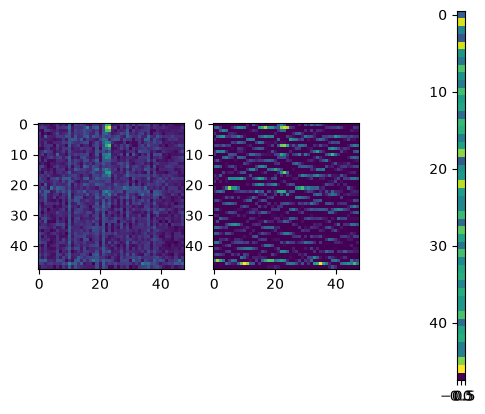

In [ ]:
N = np.random.randint(len(dataset))

def detect_horizontal_lines(image, factor=2, line_completion_threshold=0.6, use_kernel=True):
    image = image.unsqueeze(0)

    kernel = torch.tensor([
        [-1, -1, -1],
        [ 2,  2,  2],
        [-1, -1, -1]
    ], dtype=torch.float32).unsqueeze(0).unsqueeze(0)

    kernel = kernel.to(device=image.device, dtype=image.dtype)
    if use_kernel:
        response = F.conv2d(image, kernel, padding=1)
    else:
        response = image

    sum_by_lines = response.sum(dim=3, keepdim=True)

    mean, std = sum_by_lines.mean(), sum_by_lines.std()
    lines_bool = torch.where(line_completion_threshold *sum_by_lines > mean + factor*std, sum_by_lines, 0)
    
    # print(lines_bool)
    number = (lines_bool > 0).sum().item()

    return response, sum_by_lines, number

res, sum , count = detect_horizontal_lines(dataset[N]["image"])

fig, ax = plt.subplots(1,3)
ax[0].imshow(dataset[N]["image"][0,:,:])

ax[1].imshow(torch.clamp(res[0,0,:,:], min=0))
# ax[0].colorbar()

ax[2].imshow(sum[0,0,:,:])
# ax[1].colorbar()

print(count)

#### Evaluating Detection

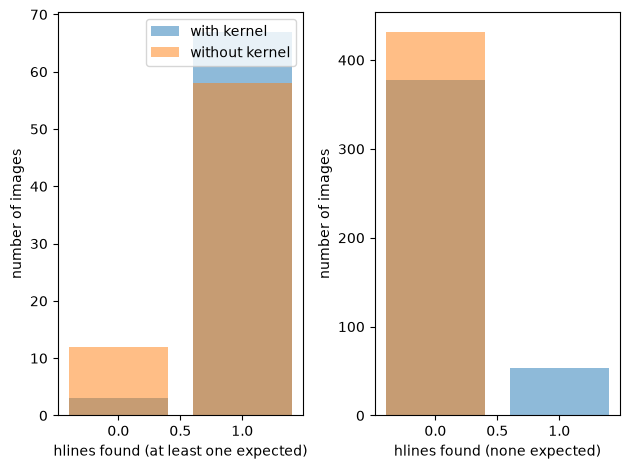

In [72]:
horizontal_found_kernel_expected = []
horizontal_found_kernel_unexpected = []
horizontal_found_no_kernel_expected = []
horizontal_found_no_kernel_unexpected = []

for entry in dataset:
    hlines_no_kernel = detect_horizontal_lines(entry["image"], use_kernel=False)[2]
    hlines_kernel = detect_horizontal_lines(entry["image"])[2]
    if entry["horizontal"]:
        horizontal_found_kernel_expected.append(hlines_kernel)
        horizontal_found_no_kernel_expected.append(hlines_no_kernel)
    else:
        horizontal_found_kernel_unexpected.append(hlines_kernel)
        horizontal_found_no_kernel_unexpected.append(hlines_no_kernel)

fig, ax = plt.subplots(1,2)
ax[0].bar(x=np.arange(max(horizontal_found_kernel_expected)+1), height=np.bincount(horizontal_found_kernel_expected), label="with kernel", alpha = 0.5)
ax[0].bar(x=np.arange(max(horizontal_found_no_kernel_expected)+1), height=np.bincount(horizontal_found_no_kernel_expected), label="without kernel", alpha = 0.5)
ax[0].set_xlabel("hlines found (at least one expected)")
ax[0].set_ylabel("number of images")
ax[0].legend()

ax[1].bar(x=np.arange(max(horizontal_found_kernel_unexpected)+1), height=np.bincount(horizontal_found_kernel_unexpected), label="with kernel", alpha = 0.5)
ax[1].bar(x=np.arange(max(horizontal_found_no_kernel_unexpected)+1), height=np.bincount(horizontal_found_no_kernel_unexpected), label="without kernel", alpha = 0.5)
ax[1].set_xlabel("hlines found (none expected)")
ax[1].set_ylabel("number of images")


plt.tight_layout()

### Testing with reconstruction-difference images

In [10]:
# from src.diffusion import diffuse
# from src.inference import (
#     load_diffusion_model,
#     make_ddim_timesteps,
#     reverse_diffusion_ddim,
# )

# from scripts.reconstruct_test_patch import resolve, load_patch

In [11]:
# MODEL = "models/unet64.pt"
# TEST_DIR = "dataset/test"
# # IMAGE = "patch_9107_22.npy"  # Horizontal
# # IMAGE = "patch_9150_13.npy"  # Other
# # IMAGE = "patch_9998_20.npy"  # Nothing
# # IMAGE = "patch_9998_11.npy"
# T_START = 600
# DDIM_STEPS = 6
# SEED = 0
# DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# test_dir = resolve(TEST_DIR)

In [12]:
# @torch.no_grad
# def run_model_inference(model_path: str,
#     image_path: str,
#     t_start: int,
#     ddim_steps: int,
#     device: str,
#     seed: int,
#     visualize: bool = True,):

#     model, schedule = load_diffusion_model(model_path, device)
#     hparams = torch.load(model_path, map_location="cpu")["hparams"]
#     T = schedule.timesteps

#     image = load_patch(image_path, hparams["data_mean"], hparams["data_std"])
#     x0 = torch.from_numpy(image)[None, None].to(device)
#     torch.manual_seed(seed)
#     t = torch.tensor([t_start], device=device)
#     xt, _ = diffuse(x0, t, schedule)

#     ddim_steps = min(ddim_steps, t_start + 1)
#     timesteps = make_ddim_timesteps(ddim_steps, T, t_start)
#     x0_hat, _ = reverse_diffusion_ddim(xt, timesteps, model, schedule)

#     # Reconstruction error
#     x0_np = x0.squeeze().cpu().numpy()
#     x0_hat_np = x0_hat.squeeze().cpu().numpy()
#     error = np.abs(x0_np - x0_hat_np)

#     return x0_hat_np


In [13]:
# N = 10
# indexes = np.random.randint(len(dataset), size=N)
# for i in indexes:
#     path_to_image = dataset[i]["filename"]
#     run_model_inference(MODEL, path_to_image, T_START, DDIM_STEPS, DEVICE, SEED)

### Rotating images 

[1, 1, 0, 1, 2, 2, 0, 1, 1, 1]


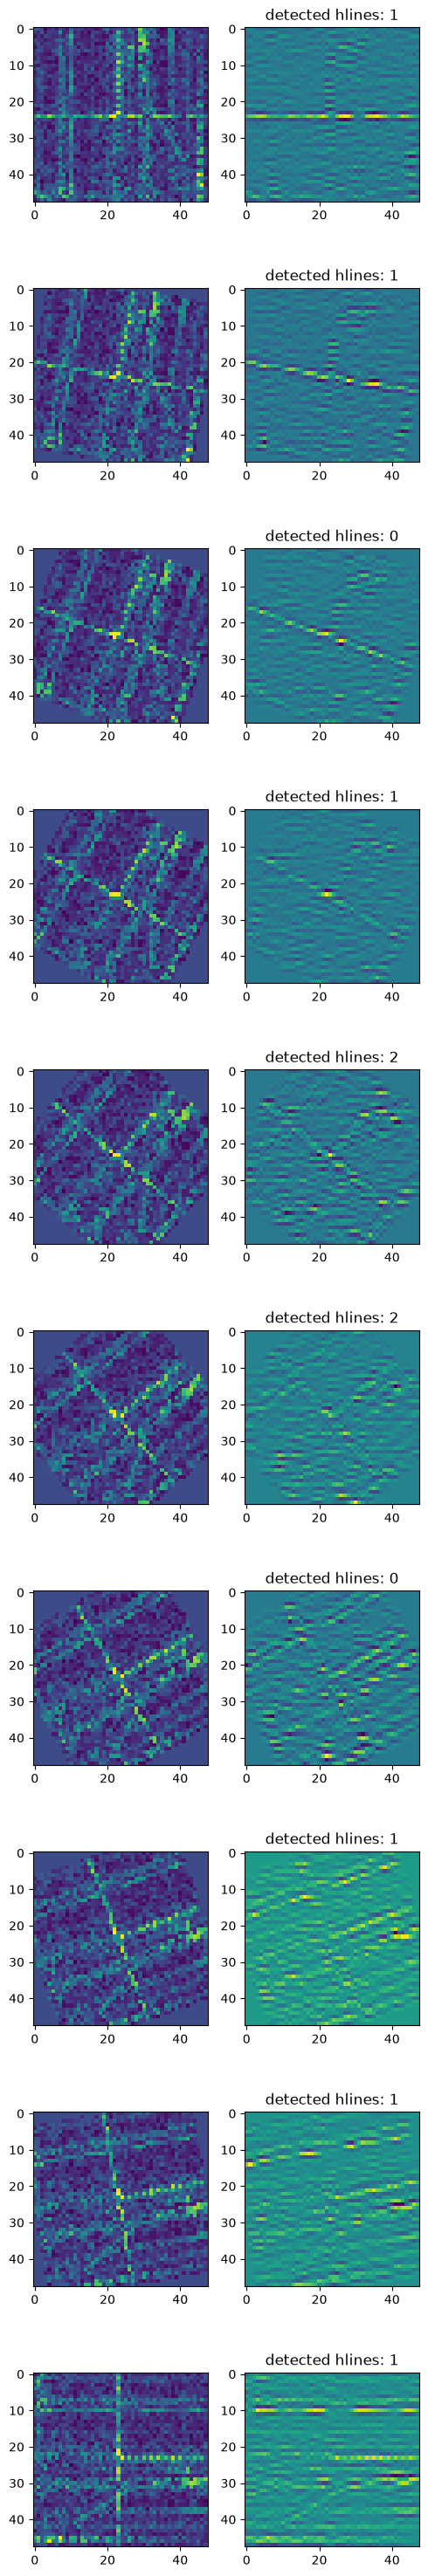

In [29]:
num = 10

fig, ax = plt.subplots(num, 2, figsize=(5, 3*num))
image = dataset[0]["image"]
angles = np.linspace(0,-90, num)
detected_hlines = []
for i in range(num):
    rotated_image = TF.rotate(image, angles[i])
    resp, _, number = detect_horizontal_lines(rotated_image)
    ax[i, 0].imshow(rotated_image[0,:,:])
    ax[i, 1].imshow(resp[0,0,:,:])
    ax[i, 1].set_title(f"detected hlines: {number}")

    detected_hlines.append(number)
print(detected_hlines)
plt.tight_layout()
